# Local Stiffness: Time vs Precision

This notebook measures the time required to obtain local element stiffness matrices $K_e$ from an input STL and compares 128³ methods with a 512³ QuESo reference.

**Timing boundary:** source STL read through final active-cell $K_e$ matrices. QuESo preprocessing, NN input preparation, classification, and inference are included. Global sparse assembly and displacement solves are excluded.

**Precision:** volume-weighted relative Frobenius error on 128³ physical cells against the restriction of the 512³ QuESo reference. The report also retains median and p95 cellwise errors so small-volume cells cannot dominate the headline.

In [2]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "clean_simulation").is_dir():
    raise RuntimeError("Open this notebook from the repository root or a descendant directory.")

OUTPUT_DIR = ROOT / "clean_simulation" / "outputs" / "local_stiffness_convergence"
SOURCE_STL = ROOT / "clean_simulation" / "geometries" / "crystal_0000.stl"
REFERENCE_RESOLUTION = 512
WORKING_RESOLUTION = 128
MATRIX_ERROR_EPS = 1.0e-12

REFERENCE_FILE = OUTPUT_DIR / f"crystal_0000_reference_trimmed_{REFERENCE_RESOLUTION}cubed.h5"
WORKING_QUESO_FILE = OUTPUT_DIR / f"crystal_0000_queso_matrices_{WORKING_RESOLUTION}cubed.h5"
CONVERGENCE_FILE = OUTPUT_DIR / "local_stiffness_convergence_512_reference.csv"
TIMING_FILE = OUTPUT_DIR / "time_vs_precision_runs.csv"

for required in (SOURCE_STL, REFERENCE_FILE, WORKING_QUESO_FILE, CONVERGENCE_FILE):
    if not required.is_file():
        raise FileNotFoundError(f"Required benchmark artifact is missing: {required}")

print(f"Geometry: {SOURCE_STL.name}")
print(f"Precision reference: QuESo {REFERENCE_RESOLUTION}^3")
print(f"Working resolution: {WORKING_RESOLUTION}^3")
print(f"Timing output: {TIMING_FILE}")

Geometry: crystal_0000.stl
Precision reference: QuESo 512^3
Working resolution: 128^3
Timing output: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\local_stiffness_convergence\time_vs_precision_runs.csv


## Benchmark Definition

For the $128^3$ candidate grid, each candidate $K_e$ will be compared to a matrix assembled from the $512^3$ QuESo integration-point reference after mapping those points into the corresponding $128^3$ cell. This avoids comparing matrices from different element domains.

The planned headline precision is the **volume-weighted relative Frobenius error**:

$$
\frac{\sum_e v_e\lVert K_e^{\mathrm{candidate}}-K_e^{\mathrm{ref}}\rVert_F}{\sum_e v_e\lVert K_e^{\mathrm{ref}}\rVert_F}.
$$

Median and p95 cellwise relative errors will be reported alongside it. Cells with a reference norm below `MATRIX_ERROR_EPS` will be excluded from cellwise ratios and counted explicitly.

The existing CSV below is retained only as a **legacy 512-reference sanity baseline**; it uses an older unweighted per-cell alignment and must not be mixed with the new headline metric.

A timing result is valid only when it includes all work from the original STL to the completed local matrices. For direct QuESo that includes STL read, QuESo embedding/quadrature, point-to-cell mapping, and matrix assembly. NN runs will additionally include source-SDF input preparation, cut-cell classification, and inference once the requested checkpoint is restored.

## Medium Transformer Error Study

This study uses the imported `256x8` ordered-SDF Transformer checkpoint whose saved held-out validation relative Frobenius loss is `0.245952%`. Evaluation follows the checkpoint's exact contract: source-STL SDF is sampled on the 128³ locked lattice, marching cubes reconstructs the mesh from that lattice, QuESo produces matrices on the reconstructed mesh, and the same lattice corner values are supplied to the model.

For each matched trimmed cell, the response is the relative Frobenius error between the NN and reconstructed-mesh QuESo $K_e$. The explanatory variables are the eight-corner lattice SDF topology, SDF proximity and variation, cell-center coordinates, and matched-QuESo stiffness norm. The report uses Spearman rank correlation; these are associations, not causal effects.

The earlier direct-source-STL comparison is intentionally superseded because it did not match the model's training geometry contract.

In [24]:
import sys

import torch

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

MEDIUM_CHECKPOINT = (
    ROOT / "clean_simulation" / "outputs" / "checkpoints" / "imported"
    / "exact_lattice_transformer_w256_l8_lbfgs_0p245952pct.pt"
)
MEDIUM_CHECKPOINT_VALIDATION_LOSS = 0.002459516885065269
MEDIUM_NORMALIZER_MEAN = torch.tensor([
    0.5057113766670227, 0.5059300661087036, 0.5057873725891113, 0.5056504607200623,
    0.5055730938911438, 0.5052542686462402, 0.5054475069046020, 0.5057997703552246,
], dtype=torch.float32)
MEDIUM_NORMALIZER_STD = torch.tensor([
    0.1789097487926483, 0.1786445081233978, 0.1788358539342880, 0.1798326969146729,
    0.1786379516124725, 0.1798913180828095, 0.1790554374456406, 0.1784338653087616,
], dtype=torch.float32)

if not MEDIUM_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Imported medium checkpoint is missing: {MEDIUM_CHECKPOINT}")
checkpoint_metadata = torch.load(MEDIUM_CHECKPOINT, map_location="cpu", weights_only=False)
if not np.isclose(checkpoint_metadata["val_loss"], MEDIUM_CHECKPOINT_VALIDATION_LOSS, rtol=0.0, atol=1.0e-15):
    raise ValueError("Imported checkpoint validation loss does not match the verified 0.245952% artifact.")

print(f"Medium checkpoint: {MEDIUM_CHECKPOINT.name}")
print(f"Saved validation relative Frobenius loss: {checkpoint_metadata['val_loss']:.6%}")
print("Normalizer: deterministic 128 x 4096 training batches from the exact-lattice corpus.")

Medium checkpoint: exact_lattice_transformer_w256_l8_lbfgs_0p245952pct.pt
Saved validation relative Frobenius loss: 0.245952%
Normalizer: deterministic 128 x 4096 training batches from the exact-lattice corpus.


In [22]:
import h5py

MATCHED_ERROR_FILE = OUTPUT_DIR / "medium_transformer_0p245952_matched_mc_cell_errors_128cubed.csv"
MATCHED_EXPLANATION_FILE = OUTPUT_DIR / "medium_transformer_0p245952_matched_mc_explanatory_summary_128cubed.csv"
LOCAL_STIFFNESS_YOUNG_MODULUS = 1.0e6


def _load_medium_transformer(device: str):
    from clean_simulation.internal_nn_runtime.cutcell_ml.model import CutCellNetTransformer

    checkpoint = torch.load(MEDIUM_CHECKPOINT, map_location="cpu", weights_only=False)
    model = CutCellNetTransformer(
        embed_dim=256,
        n_heads=8,
        n_layers=8,
        ffn_dim=1024,
        dropout=0.0,
        ordered_sdf_branch=True,
    )
    incompatible = model.load_state_dict(checkpoint["model_state_dict"], strict=False)
    if incompatible.missing_keys or incompatible.unexpected_keys:
        raise RuntimeError(f"Checkpoint/model mismatch: missing={incompatible.missing_keys}, unexpected={incompatible.unexpected_keys}")
    model.set_normalizers(MEDIUM_NORMALIZER_MEAN, MEDIUM_NORMALIZER_STD)
    return model.to(device).eval()


def run_matched_medium_transformer_error_study(*, device: str | None = None) -> pd.DataFrame:
    """Evaluate the medium Transformer under its source-lattice -> MC -> QuESo contract."""
    from clean_simulation.case import build_case_from_stl
    from clean_simulation.internal_fem_kernel.assembly.stiffness import StiffnessAssembly
    from clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws import (
        lattice_features,
        load_canonical_helpers,
        reconstructed_mesh,
        source_lattice,
    )

    study_device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    helpers = load_canonical_helpers(ROOT / "QuESo" / "out" / "install" / "win")
    helpers["DEVICE"] = study_device
    HexGrid = helpers["HexGrid"]
    Material = helpers["Material"]
    VolumeFactory = helpers["VolumeFactory"]

    with h5py.File(REFERENCE_FILE, "r") as reference_h5:
        bounds = np.asarray(reference_h5.attrs["physical_bounds"], dtype=np.float64)
    grid = HexGrid(
        bounds=(tuple(bounds[0]), tuple(bounds[1])),
        resolution=(WORKING_RESOLUTION,) * 3,
        device="cpu",
    )
    material = Material(E=LOCAL_STIFFNESS_YOUNG_MODULUS, nu=0.3)
    source_volume = VolumeFactory.from_file(SOURCE_STL)

    # This lattice is both the model input source and the sole geometry source for MC.
    lattice = source_lattice(helpers, SOURCE_STL, grid)
    rebuilt_mesh = reconstructed_mesh(helpers, lattice, grid)
    work_dir = OUTPUT_DIR / f"matched_mc_queso_{WORKING_RESOLUTION}cubed"
    work_dir.mkdir(parents=True, exist_ok=True)
    rebuilt_stl = work_dir / f"{SOURCE_STL.stem}_exact_lattice_mc_{WORKING_RESOLUTION}cubed.stl"
    rebuilt_mesh.export(rebuilt_stl)

    case = build_case_from_stl(
        stl_path=rebuilt_stl,
        workspace_root=ROOT,
        work_dir=work_dir,
        queso_python_path=ROOT / "QuESo" / "out" / "install" / "win",
        queso_basis_order=2,
        cut_cells_only=True,
        device="cpu",
        bounds_padding=0.0,
        overrides={
            "grid": {"bounds": bounds.tolist(), "resolution": [WORKING_RESOLUTION] * 3},
            "material": {"E": LOCAL_STIFFNESS_YOUNG_MODULUS, "nu": 0.3},
            "integration": {"poly_order": 1, "gauss_order": 2, "moment_fitting_residual": 1.0e-8},
        },
    )
    queso_matrices, cell_ids_t = StiffnessAssembly.compute_element_matrices_from_queso_points(
        grid=case.grid,
        material=case.material,
        ips=np.asarray(case.ips),
        poly_order=case.poly_order,
        device=study_device,
        element_batch_size=512,
    )
    cell_ids = cell_ids_t.detach().cpu().numpy().astype(np.int64)
    queso_matrices = queso_matrices.detach().cpu().numpy()
    d_values = torch.from_numpy(lattice_features(lattice, cell_ids, grid)).to(dtype=torch.float32)

    model = _load_medium_transformer(study_device)
    predictions = []
    with torch.inference_mode():
        for values in d_values.split(4096):
            predicted_unit, log_norm = model(values.to(study_device))
            predictions.append((predicted_unit * torch.exp(log_norm)[:, None, None]).cpu())
    nn_matrices = torch.cat(predictions).numpy() * (case.material.E * grid.dx)

    error_norm = np.linalg.norm(nn_matrices - queso_matrices, axis=(1, 2))
    reference_norm = np.linalg.norm(queso_matrices, axis=(1, 2))
    relative_error = error_norm / np.maximum(reference_norm, MATRIX_ERROR_EPS)
    raw_lattice_sdf = (d_values.numpy() - 0.5) * (2.0 * np.sqrt(3.0) * grid.dx)
    i = cell_ids // (WORKING_RESOLUTION ** 2)
    j = (cell_ids // WORKING_RESOLUTION) % WORKING_RESOLUTION
    k = cell_ids % WORKING_RESOLUTION
    centers = bounds[0] + (np.column_stack((i, j, k)) + 0.5) * grid.dx

    errors = pd.DataFrame({
        "cell_id": cell_ids,
        "relative_frobenius_error_vs_matched_queso": relative_error,
        "absolute_frobenius_error": error_norm,
        "matched_queso_frobenius_norm": reference_norm,
        "nn_to_queso_norm_ratio": np.linalg.norm(nn_matrices, axis=(1, 2)) / np.maximum(reference_norm, MATRIX_ERROR_EPS),
        "inside_corner_count": (d_values.numpy() > 0.5).sum(axis=1),
        "minimum_absolute_lattice_sdf": np.abs(raw_lattice_sdf).min(axis=1),
        "lattice_sdf_span": np.ptp(raw_lattice_sdf, axis=1),
        "mean_lattice_sdf": raw_lattice_sdf.mean(axis=1),
        "center_x": centers[:, 0],
        "center_y": centers[:, 1],
        "center_z": centers[:, 2],
    })
    errors.to_csv(MATCHED_ERROR_FILE, index=False)

    response = "relative_frobenius_error_vs_matched_queso"
    explanatory = [
        "inside_corner_count", "minimum_absolute_lattice_sdf", "lattice_sdf_span",
        "mean_lattice_sdf", "center_x", "center_y", "center_z", "matched_queso_frobenius_norm",
    ]
    correlations = errors[explanatory + [response]].corr(method="spearman")[response].drop(response)
    summary = pd.DataFrame({"variable": correlations.index, "spearman_rank_correlation": correlations.values})
    summary.to_csv(MATCHED_EXPLANATION_FILE, index=False)

    display(errors[[response, "nn_to_queso_norm_ratio"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
    display(summary.sort_values("spearman_rank_correlation", key=np.abs, ascending=False))
    print(f"Saved matched-contract per-cell errors to {MATCHED_ERROR_FILE}")
    print(f"Saved matched-contract explanatory summary to {MATCHED_EXPLANATION_FILE}")
    return errors


print("Run `run_matched_medium_transformer_error_study()` to evaluate the exact source-lattice and marching-cubes contract.")

Run `run_matched_medium_transformer_error_study()` to evaluate the exact source-lattice and marching-cubes contract.


In [21]:
import importlib

import clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws as exact_lattice_generator

importlib.reload(exact_lattice_generator)

<module 'clean_simulation.scripts.generate_exact_lattice_queso_dataset_aws' from 'C:\\Users\\z0058p1u\\Documents\\code\\clean_simulation\\scripts\\generate_exact_lattice_queso_dataset_aws.py'>

In [23]:
medium_error_study = run_matched_medium_transformer_error_study()

C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices: np.ndarray) -> np.ndarray:\n",
C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices: np.ndarray) -> np.ndarray:\n",
C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices: np.ndarray) -> np.ndarray:\n",
C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\01_data_generation.ipynb:125: PyVistaDeprecationWarning: This filter is deprecated. Use `select_interior_points` instead.
  "def nodal_sdf(volume, grid, flat_indices:

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.2993 seconds.
[CASE BUILD] QuESo settings write took 0.0024 seconds.
[QuESo] native grid classification and quadrature generation started.
[QuESo] native grid classification and quadrature generation complete; elapsed=22.5s.
[QuESo] Python integration-point collection started.
[QuESo] Python integration-point collection complete; elapsed=11.8s.
[CASE BUILD] QuESo total took 36.5771 seconds.
[CASE BUILD] QuESo Run() took 22.5104 seconds.
[CASE BUILD] QuESo IP extraction took 11.7946 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 10.1725s.
[CASE BUILD] QuESo weight filtering took 0.0062 seconds.
[CASE BUILD] Total case build time: 36.8867 seconds.


,relative_frobenius_error_vs_matched_queso,nn_to_queso_norm_ratio
count,49908.000000,49908.000000
mean,0.002291,0.999539
std,0.010726,0.009962
min,0.000089,0.433047
50%,0.001010,0.999841
90%,0.004841,1.000543
95%,0.007447,1.001853
99%,0.016460,1.008891
max,1.454430,2.363962


,variable,spearman_rank_correlation
7,matched_queso_frobenius_norm,-0.774811
3,mean_lattice_sdf,-0.769332
0,inside_corner_count,-0.733623
2,lattice_sdf_span,-0.278964
1,minimum_absolute_lattice_sdf,-0.241909
6,center_z,-0.024942
4,center_x,0.013569
5,center_y,-0.005894


Saved matched-contract per-cell errors to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\local_stiffness_convergence\medium_transformer_0p245952_matched_mc_cell_errors_128cubed.csv
Saved matched-contract explanatory summary to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\local_stiffness_convergence\medium_transformer_0p245952_matched_mc_explanatory_summary_128cubed.csv


## Matched-Contract Error Diagnostics

The plots below use only the valid source-lattice → marching-cubes → QuESo cells. Error is shown on a logarithmic scale because the low-error bulk and rare high-error tail differ by orders of magnitude. The spatial view highlights the worst 20 cells; the conditional summaries group continuous variables by decile and report the median and 95th-percentile error.

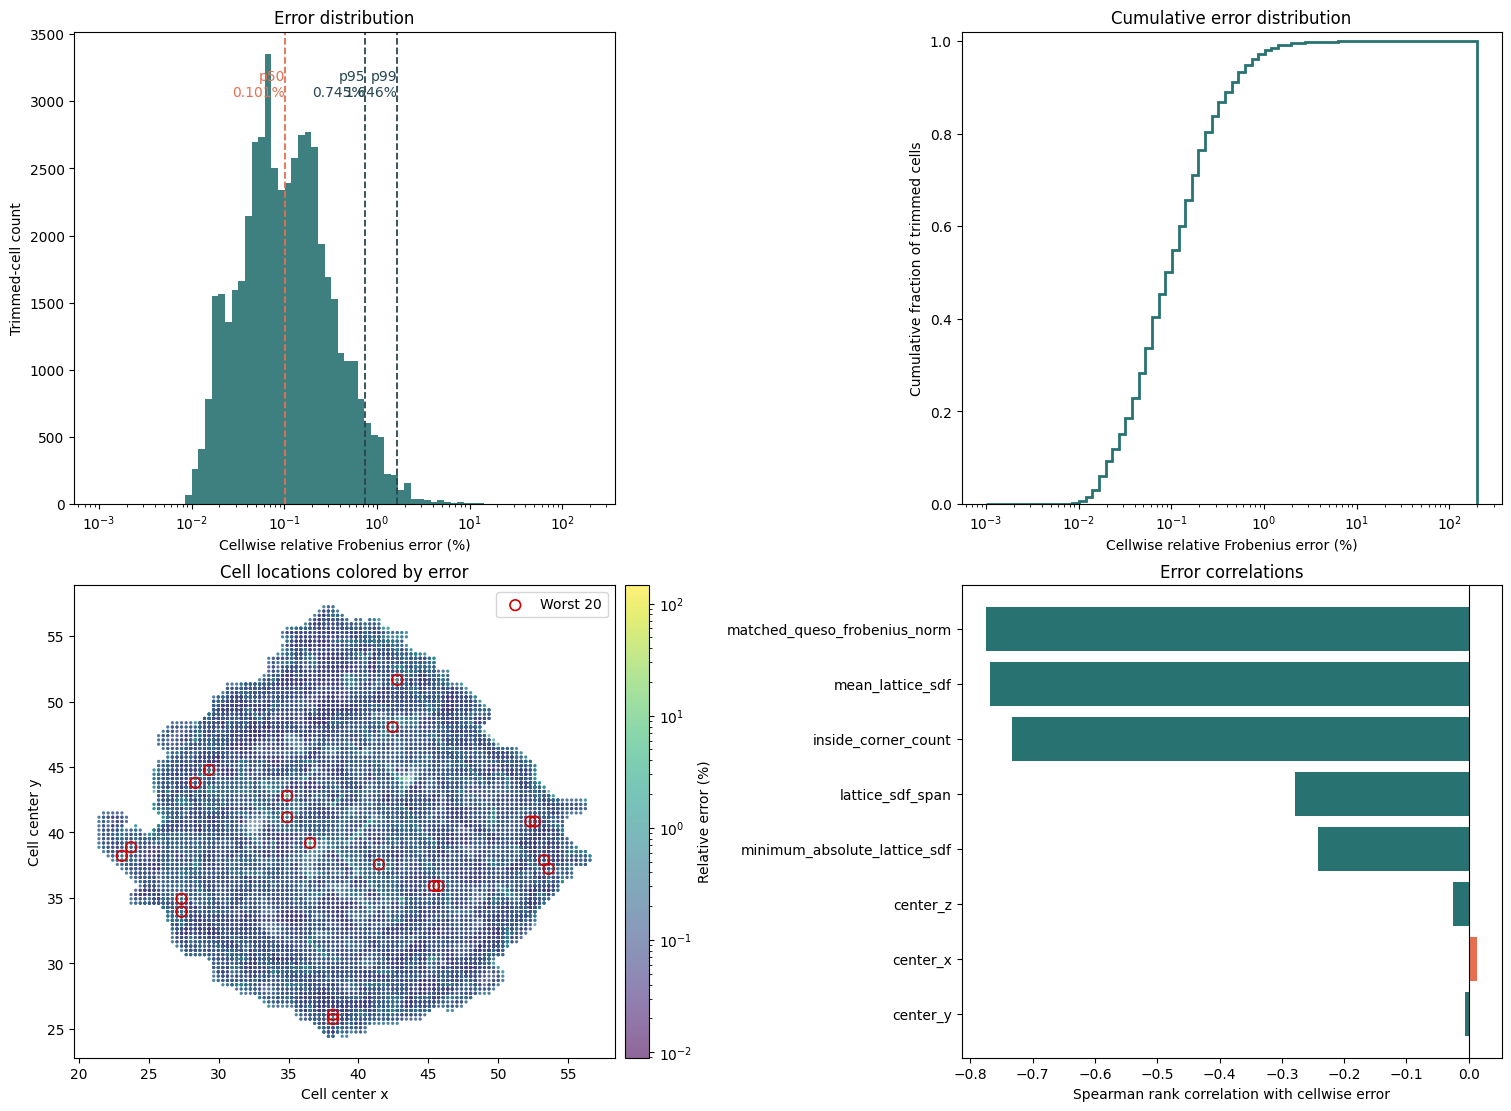

Worst 20 cells are 15.712% to 145.443% relative error.


,cell_id,relative_error_percent,absolute_frobenius_error,matched_queso_frobenius_norm,nn_to_queso_norm_ratio,inside_corner_count,minimum_absolute_lattice_sdf,lattice_sdf_span,mean_lattice_sdf,center_x,center_y,center_z
4086,517163,145.443,6.5812e+04,4.5249e+04,2.36396,2,9.4222e-03,3.9573e-01,-8.4392e-02,28.3359,43.7891,33.2734
2662,464560,74.422,1.0127e+04,1.3608e+04,1.72532,2,0.0000e+00,3.4188e-01,-1.0459e-01,27.3516,34.9297,34.9141
22234,1001659,61.449,8.9283e+04,1.4530e+05,0.43305,2,3.6084e-02,3.4616e-01,-7.0126e-02,38.1797,25.7422,38.5234
48966,1776209,59.094,1.8857e+04,3.1911e+04,1.57047,2,0.0000e+00,3.2470e-01,-1.0772e-01,53.6016,37.2266,45.7422
356,285885,58.404,6.3091e+04,1.0802e+05,0.45318,2,1.8042e-02,3.2980e-01,-8.6906e-02,23.7422,38.8672,39.1797
202,252861,49.408,4.8587e+04,9.8338e+04,0.54394,2,1.8042e-02,4.0026e-01,-1.0314e-01,23.0859,38.2109,39.1797
5904,566741,46.188,4.2698e+04,9.2445e+04,0.57780,2,1.5625e-02,4.1062e-01,-1.1737e-01,29.3203,44.7734,47.0547
15925,844518,29.737,7.2141e+03,2.4259e+04,1.28904,2,0.0000e+00,3.7125e-01,-1.5360e-01,34.8984,42.8047,52.6328
47634,1712084,29.679,1.1645e+04,3.9235e+04,1.27610,2,8.1190e-02,3.8607e-01,-9.5619e-02,52.2891,40.8359,46.7266
48154,1728467,28.924,1.1348e+04,3.9235e+04,1.26862,2,8.1190e-02,3.7889e-01,-9.4722e-02,52.6172,40.8359,46.3984


,variable,group,cells,median,p95,mean
0,inside_corner_count,1,9595,0.2248%,1.1533%,0.3752%
1,inside_corner_count,2,6929,0.2099%,1.2380%,0.4735%
2,inside_corner_count,3,2252,0.2900%,0.9909%,0.4807%
3,inside_corner_count,4,12681,0.0856%,0.3709%,0.1420%
4,inside_corner_count,5,2409,0.2090%,0.8194%,0.3486%
5,inside_corner_count,6,6145,0.0580%,0.1412%,0.0878%
6,inside_corner_count,7,9897,0.0240%,0.0637%,0.0294%
7,mean_lattice_sdf,"(-0.28, -0.198]",4991,0.4044%,1.4355%,0.5398%
8,mean_lattice_sdf,"(-0.198, -0.153]",4991,0.2248%,0.8994%,0.3428%
9,mean_lattice_sdf,"(-0.153, -0.101]",4999,0.1939%,0.8562%,0.3847%


In [26]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ERROR_COLUMN = "relative_frobenius_error_vs_matched_queso"
EXPLANATORY_COLUMNS = [
    "inside_corner_count",
    "minimum_absolute_lattice_sdf",
    "lattice_sdf_span",
    "mean_lattice_sdf",
    "center_x",
    "center_y",
    "center_z",
    "matched_queso_frobenius_norm",
]

error_diagnostics = medium_error_study.copy()
error_diagnostics["relative_error_percent"] = 100.0 * error_diagnostics[ERROR_COLUMN]
worst_cells = error_diagnostics.nlargest(20, ERROR_COLUMN).copy()
correlations = (
    error_diagnostics[EXPLANATORY_COLUMNS + [ERROR_COLUMN]]
    .corr(method="spearman")[ERROR_COLUMN]
    .drop(ERROR_COLUMN)
    .sort_values(key=np.abs, ascending=False)
)

fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

axes[0, 0].hist(error_diagnostics["relative_error_percent"], bins=np.logspace(-3, 2.3, 75), color="#287271", alpha=0.9)
axes[0, 0].set_xscale("log")
axes[0, 0].set_xlabel("Cellwise relative Frobenius error (%)")
axes[0, 0].set_ylabel("Trimmed-cell count")
axes[0, 0].set_title("Error distribution")
for percentile, color in [(0.50, "#e76f51"), (0.95, "#264653"), (0.99, "#264653")]:
    value = error_diagnostics["relative_error_percent"].quantile(percentile)
    axes[0, 0].axvline(value, color=color, linestyle="--", linewidth=1.3)
    axes[0, 0].text(value, axes[0, 0].get_ylim()[1] * 0.92, f"p{int(percentile * 100)}\n{value:.3f}%", color=color, ha="right", va="top")

axes[0, 1].hist(error_diagnostics["relative_error_percent"], bins=np.logspace(-3, 2.3, 75), density=True, cumulative=True, histtype="step", linewidth=2.0, color="#287271")
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlabel("Cellwise relative Frobenius error (%)")
axes[0, 1].set_ylabel("Cumulative fraction of trimmed cells")
axes[0, 1].set_ylim(0.0, 1.02)
axes[0, 1].set_title("Cumulative error distribution")

scatter = axes[1, 0].scatter(
    error_diagnostics["center_x"],
    error_diagnostics["center_y"],
    c=error_diagnostics["relative_error_percent"],
    s=5,
    cmap="viridis",
    norm=LogNorm(vmin=error_diagnostics["relative_error_percent"].min(), vmax=error_diagnostics["relative_error_percent"].max()),
    alpha=0.6,
    linewidths=0,
)
axes[1, 0].scatter(worst_cells["center_x"], worst_cells["center_y"], facecolors="none", edgecolors="#d00000", s=58, linewidths=1.2, label="Worst 20")
axes[1, 0].set_xlabel("Cell center x")
axes[1, 0].set_ylabel("Cell center y")
axes[1, 0].set_title("Cell locations colored by error")
axes[1, 0].legend(loc="upper right")
fig.colorbar(scatter, ax=axes[1, 0], label="Relative error (%)", pad=0.02)

correlation_colors = np.where(correlations.values < 0.0, "#287271", "#e76f51")
axes[1, 1].barh(correlations.index, correlations.values, color=correlation_colors)
axes[1, 1].axvline(0.0, color="black", linewidth=0.8)
axes[1, 1].set_xlabel("Spearman rank correlation with cellwise error")
axes[1, 1].set_title("Error correlations")
axes[1, 1].invert_yaxis()

plt.show()

conditional_summaries = []
for variable in ["inside_corner_count", "mean_lattice_sdf", "matched_queso_frobenius_norm", "lattice_sdf_span", "minimum_absolute_lattice_sdf"]:
    if variable == "inside_corner_count":
        groups = error_diagnostics[variable].astype(int)
    else:
        groups = pd.qcut(error_diagnostics[variable], q=10, duplicates="drop")
    grouped = error_diagnostics.groupby(groups, observed=True)[ERROR_COLUMN].agg(
        cells="size",
        median="median",
        p95=lambda values: values.quantile(0.95),
        mean="mean",
    ).reset_index(names="group")
    grouped.insert(0, "variable", variable)
    grouped[["median", "p95", "mean"]] *= 100.0
    conditional_summaries.append(grouped)

conditional_error_summary = pd.concat(conditional_summaries, ignore_index=True)
worst_cell_table = worst_cells[[
    "cell_id", "relative_error_percent", "absolute_frobenius_error", "matched_queso_frobenius_norm",
    "nn_to_queso_norm_ratio", "inside_corner_count", "minimum_absolute_lattice_sdf", "lattice_sdf_span",
    "mean_lattice_sdf", "center_x", "center_y", "center_z",
]].sort_values("relative_error_percent", ascending=False)

print(f"Worst 20 cells are {worst_cells[ERROR_COLUMN].min():.3%} to {worst_cells[ERROR_COLUMN].max():.3%} relative error.")
display(worst_cell_table.style.format({
    "relative_error_percent": "{:.3f}",
    "absolute_frobenius_error": "{:.4e}",
    "matched_queso_frobenius_norm": "{:.4e}",
    "nn_to_queso_norm_ratio": "{:.5f}",
    "minimum_absolute_lattice_sdf": "{:.4e}",
    "lattice_sdf_span": "{:.4e}",
    "mean_lattice_sdf": "{:.4e}",
    "center_x": "{:.4f}",
    "center_y": "{:.4f}",
    "center_z": "{:.4f}",
}))
display(conditional_error_summary.style.format({"median": "{:.4f}%", "p95": "{:.4f}%", "mean": "{:.4f}%"}))

## Hanging-Sphere Displacement Diagnostics

This separate diagnostic evaluates the archived $128^3$ hanging-sphere NN and QuESo fields from the `physical_fixed_support_local` run. Every displacement metric uses the intersection of nodes incident to the archived active cells, independently reconstructed for both fields; nodes outside that common physical support are excluded. To remain stable at constrained or near-zero-displacement nodes, nodewise vector error is normalized by the maximum QuESo displacement magnitude over that support, rather than dividing independently by each nodal magnitude.

To identify the input regimes associated with nodal errors, the notebook reuses the archived study STL and its archived QuESo cut-cell indices, then runs the same mesh-based `prepare_nn_inputs` SDF procedure that fed the NN. A node is assigned an SDF feature only when it is incident to at least one NN-predicted cut cell. The model-input analysis therefore does not infer signed distance from the hanging-sphere formula and does not attribute an input feature to nodes whose incident matrices were all analytic full-cell matrices. Grid coordinates are normalized to $[0, 1]^3$ only for spatial plotting. These displacement results are a benchmark-field diagnostic and are not a displacement solve for the medium crystal checkpoint above.

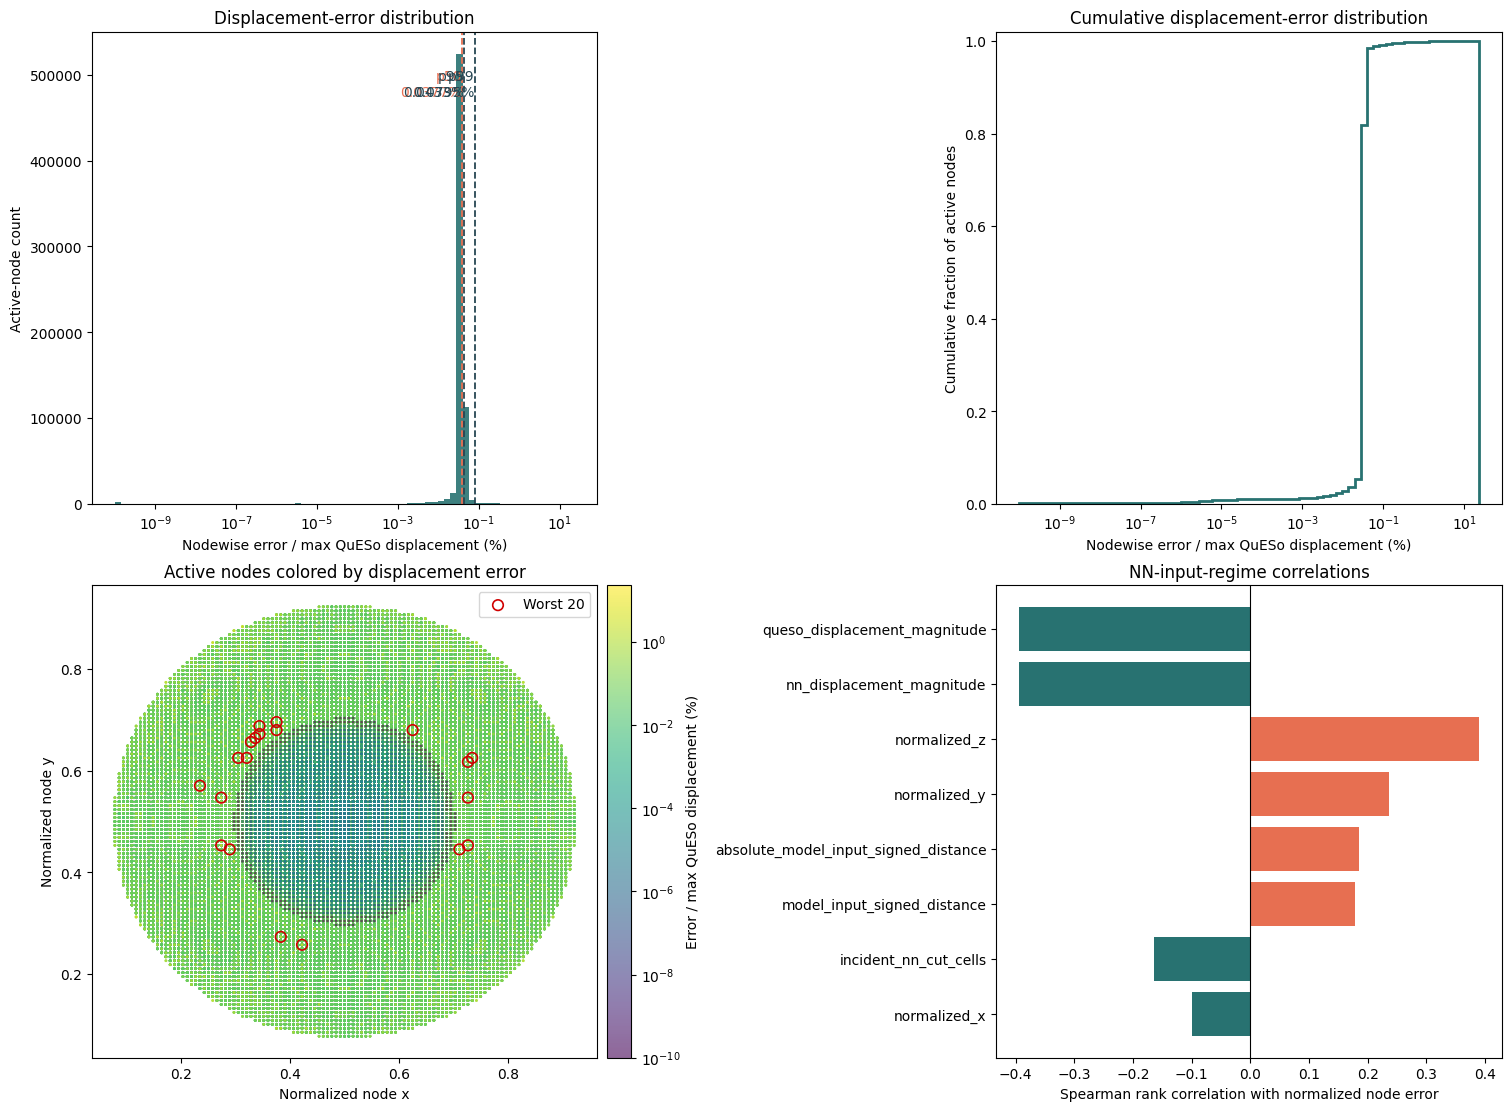

QuESo physical active nodes: 686,301
NN physical active nodes: 686,301
Shared physical active nodes used by displacement metrics: 686,301
Excluded QuESo-only nodes: 0
Excluded NN-only nodes: 0
Nodes incident to NN-predicted cut cells: 104,452
Nodes below the plot floor (1e-10%): 2,161
NN vs QuESo relative L2 displacement error: 0.1780%
Worst 20 normalized node errors: 8.632% to 22.925%
Highest p95 NN-input signed-distance regime: (0.161, 0.227]; p95=2.3076%, mean=0.4493%


,population,nodes,spearman_rank,pearson
0,shared physical nodes,686301,-0.0393,0.0185
1,NN-predicted cut-cell nodes,104452,-0.3940,-0.0125


,node_id,normalized_node_error_percent,nodewise_relative_error,absolute_node_error,queso_displacement_magnitude,nn_displacement_magnitude,model_input_signed_distance,absolute_model_input_signed_distance,incident_nn_cut_cells,normalized_x,normalized_y,normalized_z
96729,591575,22.9252,50.5520%,3.8567e-03,7.6292e-03,1.0140e-02,0.19969,0.19969,1,0.2734,0.5469,0.8594
141526,692712,18.4452,41.4899%,3.1030e-03,7.4790e-03,9.1083e-03,0.19968,0.19968,1,0.3203,0.6250,0.8672
589663,1555205,17.6820,38.9899%,2.9746e-03,7.6292e-03,8.0264e-03,0.19969,0.19969,1,0.7266,0.4531,0.8594
65359,508753,16.2992,25.6060%,2.7420e-03,1.0708e-02,1.2554e-02,0.20562,0.20562,1,0.2344,0.5703,0.8281
590779,1556753,15.8251,34.8957%,2.6622e-03,7.6291e-03,8.7214e-03,0.19969,0.19969,1,0.7266,0.5469,0.8594
199781,810102,13.7089,30.5504%,2.3062e-03,7.5490e-03,7.9632e-03,0.19924,0.19924,1,0.3750,0.6797,0.8672
95613,590027,13.0852,28.8537%,2.2013e-03,7.6292e-03,8.0824e-03,0.19969,0.19969,1,0.2734,0.4531,0.8594
575625,1521795,12.1383,27.9879%,2.0420e-03,7.2961e-03,7.5915e-03,0.19296,0.19296,1,0.7109,0.4453,0.8672
166054,743408,11.8232,25.2925%,1.9890e-03,7.8640e-03,8.2862e-03,0.20876,0.20876,1,0.3438,0.6719,0.8594
199967,810359,11.7198,24.5450%,1.9716e-03,8.0327e-03,8.5662e-03,0.20387,0.20387,1,0.3750,0.6953,0.8594


,variable,group,nodes,median,p95,mean
0,queso_displacement_magnitude,"(-0.001, 0.00987]",10446,0.0145%,0.1144%,0.1021%
1,queso_displacement_magnitude,"(0.00987, 0.0127]",10445,0.0436%,0.3106%,0.1284%
2,queso_displacement_magnitude,"(0.0127, 0.0136]",10445,0.0409%,0.2587%,0.1252%
3,queso_displacement_magnitude,"(0.0136, 0.014]",10445,0.0401%,0.3211%,0.1130%
4,queso_displacement_magnitude,"(0.014, 0.0143]",10445,0.0395%,0.0970%,0.0775%
5,queso_displacement_magnitude,"(0.0143, 0.0146]",10445,0.0391%,0.0679%,0.0575%
6,queso_displacement_magnitude,"(0.0146, 0.015]",10445,0.0388%,0.1123%,0.0548%
7,queso_displacement_magnitude,"(0.015, 0.0155]",10445,0.0384%,0.0710%,0.0515%
8,queso_displacement_magnitude,"(0.0155, 0.016]",10445,0.0380%,0.0638%,0.0479%
9,queso_displacement_magnitude,"(0.016, 0.0168]",10446,0.0375%,0.0548%,0.0440%


In [9]:
from matplotlib.colors import LogNorm
import sys

import torch

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from clean_simulation.bootstrap import configure_legacy_imports
from clean_simulation.internal_nn_runtime.cutcell_bridge import prepare_nn_inputs

DISPLACEMENT_ARCHIVE_DIR = (
    ROOT / "clean_simulation" / "outputs" / "sphere_displacement_convergence_physical_fixed_support_local"
    / "planar_cap_plane_hard_constraints"
)
DISPLACEMENT_RESOLUTION = 128
DISPLACEMENT_BOUNDS = np.array(((-9.0, -9.0, -9.0), (9.0, 9.0, 9.0)), dtype=np.float64)
DISPLACEMENT_MESH_DIR = DISPLACEMENT_ARCHIVE_DIR.parent / f"queso_matrix_free_{DISPLACEMENT_RESOLUTION}cubed"
DISPLACEMENT_STL = DISPLACEMENT_MESH_DIR / "study_geometry_surface.stl"
DISPLACEMENT_CUT_CACHE = DISPLACEMENT_MESH_DIR / "queso_cut_stiffness.pt"
NODEWISE_REFERENCE_FLOOR_FRACTION = 1.0e-4
ERROR_PLOT_FLOOR_PERCENT = 1.0e-10


def active_node_ids(active_cells: np.ndarray, resolution: int) -> np.ndarray:
    cells = np.unique(np.asarray(active_cells, dtype=np.int64))
    node_side = resolution + 1
    i = cells // (resolution * resolution)
    j = (cells // resolution) % resolution
    k = cells % resolution
    base = (i * node_side + j) * node_side + k
    offsets = np.array((
        0, node_side * node_side, node_side * node_side + node_side, node_side,
        1, node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1,
    ))
    return np.unique((base[:, None] + offsets).reshape(-1))


def load_archived_displacement_field(framework: str) -> dict[str, np.ndarray]:
    archive_path = DISPLACEMENT_ARCHIVE_DIR / f"hanging_sphere_{framework}_displacement_{DISPLACEMENT_RESOLUTION}cubed.npz"
    if not archive_path.is_file():
        raise FileNotFoundError(f"Missing archived displacement field: {archive_path}")
    with np.load(archive_path, allow_pickle=True) as archive:
        return {
            "u_nodes": np.asarray(archive["u_nodes"], dtype=np.float64),
            "active_cells": np.asarray(archive["active_cells"], dtype=np.int64),
            "active_nodes": np.asarray(archive["active_nodes"], dtype=np.int64),
        }


def model_input_sdf_by_node() -> tuple[np.ndarray, np.ndarray]:
    """Return raw model-input SDF and incident predicted-cut-cell counts per grid node."""
    if not DISPLACEMENT_STL.is_file() or not DISPLACEMENT_CUT_CACHE.is_file():
        raise FileNotFoundError("The archived study STL and QuESo cut-cell cache are required for model-input diagnostics.")
    configure_legacy_imports(ROOT)
    from constants import Material
    from geometry import HexGrid
    from volume_factory import VolumeFactory

    grid = HexGrid(bounds=DISPLACEMENT_BOUNDS.tolist(), resolution=[DISPLACEMENT_RESOLUTION] * 3, device="cpu")
    volume = VolumeFactory.from_file(DISPLACEMENT_STL)
    cut_cache = torch.load(DISPLACEMENT_CUT_CACHE, map_location="cpu", weights_only=True)
    cut_cells = cut_cache["indices"].to(dtype=torch.int64)
    d_normalized, _, h_ref = prepare_nn_inputs(
        grid=grid,
        volume=volume,
        partial_indices=cut_cells,
        material=Material(E=1.0e6, nu=0.3),
        poly_order=1,
        sdf_device="cuda" if torch.cuda.is_available() else "cpu",
    )
    raw_sdf = (0.5 - d_normalized.numpy()) * (2.0 * np.sqrt(3.0) * h_ref)
    cell_ids = cut_cells.numpy()
    node_side = DISPLACEMENT_RESOLUTION + 1
    i = cell_ids // (DISPLACEMENT_RESOLUTION ** 2)
    j = (cell_ids // DISPLACEMENT_RESOLUTION) % DISPLACEMENT_RESOLUTION
    k = cell_ids % DISPLACEMENT_RESOLUTION
    base = (i * node_side + j) * node_side + k
    offsets = np.array((
        0, node_side * node_side, node_side * node_side + node_side, node_side,
        1, node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1,
    ))
    cell_node_ids = (base[:, None] + offsets).reshape(-1)
    node_sdf_sum = np.zeros(node_side ** 3, dtype=np.float64)
    node_sdf_count = np.zeros(node_side ** 3, dtype=np.int64)
    np.add.at(node_sdf_sum, cell_node_ids, raw_sdf.reshape(-1))
    np.add.at(node_sdf_count, cell_node_ids, 1)
    mean_sdf = np.full(node_side ** 3, np.nan)
    np.divide(node_sdf_sum, node_sdf_count, out=mean_sdf, where=node_sdf_count > 0)
    return mean_sdf, node_sdf_count


queso_displacement = load_archived_displacement_field("queso")
nn_displacement = load_archived_displacement_field("nn")
queso_active_nodes = active_node_ids(queso_displacement["active_cells"], DISPLACEMENT_RESOLUTION)
nn_active_nodes = active_node_ids(nn_displacement["active_cells"], DISPLACEMENT_RESOLUTION)
common_active_nodes = np.intersect1d(queso_active_nodes, nn_active_nodes, assume_unique=True)
queso_only_nodes = np.setdiff1d(queso_active_nodes, common_active_nodes, assume_unique=True)
nn_only_nodes = np.setdiff1d(nn_active_nodes, common_active_nodes, assume_unique=True)

if not np.array_equal(np.unique(queso_displacement["active_nodes"]), queso_active_nodes):
    raise RuntimeError("QuESo archive active_nodes does not match the nodes incident to its active cells.")
if not np.array_equal(np.unique(nn_displacement["active_nodes"]), nn_active_nodes):
    raise RuntimeError("NN archive active_nodes does not match the nodes incident to its active cells.")
if not len(common_active_nodes):
    raise RuntimeError("The archived NN and QuESo fields have no common physical active-node support.")

active_nodes = common_active_nodes
reference_u = queso_displacement["u_nodes"][active_nodes]
predicted_u = nn_displacement["u_nodes"][active_nodes]
reference_magnitude = np.linalg.norm(reference_u, axis=1)
absolute_node_error = np.linalg.norm(predicted_u - reference_u, axis=1)
reference_peak = max(float(reference_magnitude.max()), np.finfo(np.float64).tiny)
nodewise_error_percent = 100.0 * absolute_node_error / reference_peak
reference_floor = reference_peak * NODEWISE_REFERENCE_FLOOR_FRACTION
valid_relative_nodes = reference_magnitude > reference_floor
nodewise_relative_error = np.full(len(active_nodes), np.nan)
nodewise_relative_error[valid_relative_nodes] = absolute_node_error[valid_relative_nodes] / reference_magnitude[valid_relative_nodes]

node_side = DISPLACEMENT_RESOLUTION + 1
i = active_nodes // (node_side * node_side)
j = (active_nodes // node_side) % node_side
k = active_nodes % node_side
node_indices = np.column_stack((i, j, k))
model_input_sdf, incident_cut_cell_count = model_input_sdf_by_node()
nodal_model_sdf = model_input_sdf[active_nodes]
nodal_cut_cell_count = incident_cut_cell_count[active_nodes]

# Raw SDF is exactly the mesh-based value inverted from the normalized NN input.
displacement_diagnostics = pd.DataFrame({
    "node_id": active_nodes,
    "normalized_node_error_percent": nodewise_error_percent,
    "nodewise_relative_error": nodewise_relative_error,
    "absolute_node_error": absolute_node_error,
    "queso_displacement_magnitude": reference_magnitude,
    "nn_displacement_magnitude": np.linalg.norm(predicted_u, axis=1),
    "model_input_signed_distance": nodal_model_sdf,
    "absolute_model_input_signed_distance": np.abs(nodal_model_sdf),
    "incident_nn_cut_cells": nodal_cut_cell_count,
    "normalized_x": node_indices[:, 0] / DISPLACEMENT_RESOLUTION,
    "normalized_y": node_indices[:, 1] / DISPLACEMENT_RESOLUTION,
    "normalized_z": node_indices[:, 2] / DISPLACEMENT_RESOLUTION,
})
DISPLACEMENT_ERROR_COLUMN = "normalized_node_error_percent"
model_input_nodes = displacement_diagnostics.loc[displacement_diagnostics["incident_nn_cut_cells"] > 0].copy()
DISPLACEMENT_EXPLANATORY_COLUMNS = [
    "queso_displacement_magnitude",
    "nn_displacement_magnitude",
    "model_input_signed_distance",
    "absolute_model_input_signed_distance",
    "incident_nn_cut_cells",
    "normalized_x",
    "normalized_y",
    "normalized_z",
]
displacement_correlations = (
    model_input_nodes[DISPLACEMENT_EXPLANATORY_COLUMNS + [DISPLACEMENT_ERROR_COLUMN]]
    .corr(method="spearman")[DISPLACEMENT_ERROR_COLUMN]
    .drop(DISPLACEMENT_ERROR_COLUMN)
    .sort_values(key=np.abs, ascending=False)
)
reference_error_correlations = pd.DataFrame({
    "population": ["shared physical nodes", "NN-predicted cut-cell nodes"],
    "nodes": [len(displacement_diagnostics), len(model_input_nodes)],
    "spearman_rank": [
        displacement_diagnostics["queso_displacement_magnitude"].corr(displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN], method="spearman"),
        model_input_nodes["queso_displacement_magnitude"].corr(model_input_nodes[DISPLACEMENT_ERROR_COLUMN], method="spearman"),
    ],
    "pearson": [
        displacement_diagnostics["queso_displacement_magnitude"].corr(displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN], method="pearson"),
        model_input_nodes["queso_displacement_magnitude"].corr(model_input_nodes[DISPLACEMENT_ERROR_COLUMN], method="pearson"),
    ],
})
worst_displacement_nodes = displacement_diagnostics.nlargest(20, DISPLACEMENT_ERROR_COLUMN)
plot_errors = displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN].clip(lower=ERROR_PLOT_FLOOR_PERCENT)
error_floor_count = int((displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN] < ERROR_PLOT_FLOOR_PERCENT).sum())

fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)
error_ceiling = float(displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN].max())
bins = np.logspace(np.log10(ERROR_PLOT_FLOOR_PERCENT), np.log10(error_ceiling), 75)
axes[0, 0].hist(plot_errors, bins=bins, color="#287271", alpha=0.9)
axes[0, 0].set_xscale("log")
axes[0, 0].set(xlabel="Nodewise error / max QuESo displacement (%)", ylabel="Active-node count", title="Displacement-error distribution")
for percentile, color in [(0.50, "#e76f51"), (0.95, "#264653"), (0.99, "#264653")]:
    value = max(float(displacement_diagnostics[DISPLACEMENT_ERROR_COLUMN].quantile(percentile)), ERROR_PLOT_FLOOR_PERCENT)
    axes[0, 0].axvline(value, color=color, linestyle="--", linewidth=1.3)
    axes[0, 0].text(value, axes[0, 0].get_ylim()[1] * 0.92, f"p{int(percentile * 100)}\n{value:.3g}%", color=color, ha="right", va="top")

axes[0, 1].hist(plot_errors, bins=bins, density=True, cumulative=True, histtype="step", linewidth=2.0, color="#287271")
axes[0, 1].set_xscale("log")
axes[0, 1].set(xlabel="Nodewise error / max QuESo displacement (%)", ylabel="Cumulative fraction of active nodes", ylim=(0.0, 1.02), title="Cumulative displacement-error distribution")

scatter = axes[1, 0].scatter(
    displacement_diagnostics["normalized_x"], displacement_diagnostics["normalized_y"], c=plot_errors,
    s=4, cmap="viridis", norm=LogNorm(vmin=ERROR_PLOT_FLOOR_PERCENT, vmax=error_ceiling), alpha=0.6, linewidths=0,
)
axes[1, 0].scatter(worst_displacement_nodes["normalized_x"], worst_displacement_nodes["normalized_y"], facecolors="none", edgecolors="#d00000", s=58, linewidths=1.2, label="Worst 20")
axes[1, 0].set(xlabel="Normalized node x", ylabel="Normalized node y", title="Active nodes colored by displacement error")
axes[1, 0].legend(loc="upper right")
fig.colorbar(scatter, ax=axes[1, 0], label="Error / max QuESo displacement (%)", pad=0.02)

correlation_colors = np.where(displacement_correlations.values < 0.0, "#287271", "#e76f51")
axes[1, 1].barh(displacement_correlations.index, displacement_correlations.values, color=correlation_colors)
axes[1, 1].axvline(0.0, color="black", linewidth=0.8)
axes[1, 1].set(xlabel="Spearman rank correlation with normalized node error", title="NN-input-regime correlations")
axes[1, 1].invert_yaxis()
plt.show()

conditional_displacement_summaries = []
for variable in ["queso_displacement_magnitude", "model_input_signed_distance", "absolute_model_input_signed_distance", "normalized_z"]:
    groups = pd.qcut(model_input_nodes[variable], q=10, duplicates="drop")
    grouped = model_input_nodes.groupby(groups, observed=True)[DISPLACEMENT_ERROR_COLUMN].agg(
        nodes="size", median="median", p95=lambda values: values.quantile(0.95), mean="mean",
    ).reset_index(names="group")
    grouped.insert(0, "variable", variable)
    conditional_displacement_summaries.append(grouped)

conditional_displacement_summary = pd.concat(conditional_displacement_summaries, ignore_index=True)
signed_distance_summary = conditional_displacement_summary.loc[
    conditional_displacement_summary["variable"] == "model_input_signed_distance"
]
worst_signed_distance_regime = signed_distance_summary.loc[signed_distance_summary["p95"].idxmax()]
worst_displacement_node_table = worst_displacement_nodes[[
    "node_id", "normalized_node_error_percent", "nodewise_relative_error", "absolute_node_error",
    "queso_displacement_magnitude", "nn_displacement_magnitude", "model_input_signed_distance",
    "absolute_model_input_signed_distance", "incident_nn_cut_cells", "normalized_x", "normalized_y", "normalized_z",
]].sort_values(DISPLACEMENT_ERROR_COLUMN, ascending=False)

relative_l2_displacement_error = np.linalg.norm(predicted_u - reference_u) / max(np.linalg.norm(reference_u), np.finfo(np.float64).tiny)
print(f"QuESo physical active nodes: {len(queso_active_nodes):,}")
print(f"NN physical active nodes: {len(nn_active_nodes):,}")
print(f"Shared physical active nodes used by displacement metrics: {len(active_nodes):,}")
print(f"Excluded QuESo-only nodes: {len(queso_only_nodes):,}")
print(f"Excluded NN-only nodes: {len(nn_only_nodes):,}")
print(f"Nodes incident to NN-predicted cut cells: {len(model_input_nodes):,}")
print(f"Nodes below the plot floor ({ERROR_PLOT_FLOOR_PERCENT:.0e}%): {error_floor_count:,}")
print(f"NN vs QuESo relative L2 displacement error: {relative_l2_displacement_error:.4%}")
print(f"Worst 20 normalized node errors: {worst_displacement_nodes[DISPLACEMENT_ERROR_COLUMN].min():.3f}% to {worst_displacement_nodes[DISPLACEMENT_ERROR_COLUMN].max():.3f}%")
print(f"Highest p95 NN-input signed-distance regime: {worst_signed_distance_regime.group}; p95={worst_signed_distance_regime.p95:.4f}%, mean={worst_signed_distance_regime['mean']:.4f}%")
display(reference_error_correlations.style.format({"spearman_rank": "{:.4f}", "pearson": "{:.4f}"}))
display(worst_displacement_node_table.style.format({
    "normalized_node_error_percent": "{:.4f}", "nodewise_relative_error": "{:.4%}", "absolute_node_error": "{:.4e}",
    "queso_displacement_magnitude": "{:.4e}", "nn_displacement_magnitude": "{:.4e}",
    "model_input_signed_distance": "{:.5f}", "absolute_model_input_signed_distance": "{:.5f}",
    "normalized_x": "{:.4f}", "normalized_y": "{:.4f}", "normalized_z": "{:.4f}",
}))
display(conditional_displacement_summary.style.format({"median": "{:.4f}%", "p95": "{:.4f}%", "mean": "{:.4f}%"}))

In [4]:
legacy_baseline = pd.read_csv(CONVERGENCE_FILE)
legacy_128 = legacy_baseline.loc[
    (legacy_baseline["resolution"] == WORKING_RESOLUTION)
    & (legacy_baseline["method"].isin(["queso", "nn", "naive", "weighted"])),
    ["method", "cells", "mean_relative_error", "median_relative_error", "p95_relative_error", "max_relative_error"],
].copy()
legacy_128 = legacy_128.rename(columns={
    "mean_relative_error": "legacy_mean_cellwise_relative_error",
    "median_relative_error": "legacy_median_cellwise_relative_error",
    "p95_relative_error": "legacy_p95_cellwise_relative_error",
    "max_relative_error": "legacy_max_cellwise_relative_error",
})
legacy_128["reference"] = f"QuESo {REFERENCE_RESOLUTION}^3"
legacy_128["candidate_resolution"] = WORKING_RESOLUTION
legacy_128 = legacy_128.sort_values("method").reset_index(drop=True)

display(legacy_128.style.format({
    "legacy_mean_cellwise_relative_error": "{:.3%}",
    "legacy_median_cellwise_relative_error": "{:.3%}",
    "legacy_p95_cellwise_relative_error": "{:.3%}",
    "legacy_max_cellwise_relative_error": "{:.3%}",
}))

legacy_queso_128 = legacy_128.loc[legacy_128["method"] == "queso"].iloc[0]
print(
    "Legacy, unweighted cellwise baseline only: "
    f"QuESo {WORKING_RESOLUTION}^3 versus {REFERENCE_RESOLUTION}^3 has "
    f"median={legacy_queso_128.legacy_median_cellwise_relative_error:.3%}, "
    f"mean={legacy_queso_128.legacy_mean_cellwise_relative_error:.3%}, "
    f"p95={legacy_queso_128.legacy_p95_cellwise_relative_error:.3%}."
)

,method,cells,legacy_mean_cellwise_relative_error,legacy_median_cellwise_relative_error,legacy_p95_cellwise_relative_error,legacy_max_cellwise_relative_error,reference,candidate_resolution
0,naive,51999,2048.793%,541.146%,9139.817%,50757.122%,QuESo 512^3,128
1,nn,50823,312.381%,115.088%,1152.023%,5765.697%,QuESo 512^3,128
2,queso,51999,310.741%,109.789%,1152.018%,5679.213%,QuESo 512^3,128
3,weighted,51999,341.497%,118.927%,1149.763%,5663.760%,QuESo 512^3,128


Legacy, unweighted cellwise baseline only: QuESo 128^3 versus 512^3 has median=109.789%, mean=310.741%, p95=1152.018%.


In [3]:
from dataclasses import asdict, dataclass
from time import perf_counter

import importlib
import torch

@dataclass(frozen=True)
class LocalKeTiming:
    method: str
    geometry: str
    resolution: int
    source_stl_s: float
    queso_preprocess_s: float
    input_preparation_s: float
    classification_s: float
    inference_s: float
    local_ke_assembly_s: float
    active_cells: int
    device: str

    @property
    def total_s(self) -> float:
        return (
            self.source_stl_s + self.queso_preprocess_s + self.input_preparation_s
            + self.classification_s + self.inference_s + self.local_ke_assembly_s
        )


def append_timing(result: LocalKeTiming) -> pd.DataFrame:
    row = asdict(result) | {"total_s": result.total_s}
    history = pd.read_csv(TIMING_FILE) if TIMING_FILE.is_file() else pd.DataFrame()
    history = pd.concat((history, pd.DataFrame([row])), ignore_index=True)
    history.to_csv(TIMING_FILE, index=False)
    return history


def benchmark_direct_queso_local_ke(*, resolution: int = WORKING_RESOLUTION, device: str = "cpu") -> LocalKeTiming:
    """Time source STL through direct-QuESo local stiffness matrices; excludes global solve."""
    import clean_simulation.case as case_module
    from clean_simulation.internal_fem_kernel.assembly.stiffness import StiffnessAssembly

    case_module = importlib.reload(case_module)
    started = perf_counter()
    case = case_module.build_case_from_stl(
        stl_path=SOURCE_STL,
        workspace_root=ROOT,
        work_dir=OUTPUT_DIR / f"timing_queso_{resolution}cubed",
        queso_python_path=ROOT / "QuESo" / "out" / "install" / "win",
        queso_basis_order=2,
        device=device,
        overrides={
            "grid": {"resolution": [resolution, resolution, resolution]},
            "integration": {"poly_order": 1, "gauss_order": 2, "moment_fitting_residual": 1.0e-8},
        },
    )
    queso_ready = perf_counter()

    if torch.cuda.is_available() and str(device).startswith("cuda"):
        torch.cuda.synchronize()
    matrices, active_cells = StiffnessAssembly.compute_element_matrices_from_queso_points_fast(
        grid=case.grid,
        material=case.material,
        ips=np.asarray(case.ips),
        trimmed_ip_mask=np.asarray(case.queso_metadata["trimmed_ip_mask"], dtype=bool),
        poly_order=case.poly_order,
        order=case.g_order,
        device=device,
        element_batch_size=512,
    )
    if torch.cuda.is_available() and str(device).startswith("cuda"):
        torch.cuda.synchronize()
    finished = perf_counter()

    result = LocalKeTiming(
        method="queso_direct_stl",
        geometry=SOURCE_STL.stem,
        resolution=resolution,
        source_stl_s=0.0,
        queso_preprocess_s=queso_ready - started,
        input_preparation_s=0.0,
        classification_s=0.0,
        inference_s=0.0,
        local_ke_assembly_s=finished - queso_ready,
        active_cells=int(len(active_cells)),
        device=str(device),
    )
    print(f"Completed {len(matrices)} direct-QuESo local matrices in {result.total_s:.2f}s.")
    return result

print("Run `append_timing(benchmark_direct_queso_local_ke())` to record a fresh end-to-end QuESo timing.")

Run `append_timing(benchmark_direct_queso_local_ke())` to record a fresh end-to-end QuESo timing.


In [8]:
from time import perf_counter

import h5py
import importlib

PRECISION_FILE = OUTPUT_DIR / "time_vs_precision_accuracy.csv"


def _build_reference_grid(resolution: int):
    """Build the shared FEM grid without invoking QuESo again."""
    import clean_simulation.case as case_module

    case_module.configure_legacy_imports(ROOT)
    Material = importlib.import_module("constants").Material
    HexGrid = importlib.import_module("geometry").HexGrid

    with h5py.File(REFERENCE_FILE, "r") as reference_h5:
        bounds = np.asarray(reference_h5.attrs["physical_bounds"], dtype=np.float64)
    grid = HexGrid(
        bounds=(tuple(bounds[0]), tuple(bounds[1])),
        resolution=(resolution, resolution, resolution),
        device="cpu",
    )
    return grid, Material(E=1.0e5, nu=0.3)


def _flat_parent_cells(points: np.ndarray, *, bounds: np.ndarray, resolution: int) -> np.ndarray:
    scaled = (points[:, :3] - bounds[0]) / (bounds[1] - bounds[0])
    ijk = np.clip(np.floor(scaled * resolution).astype(np.int64), 0, resolution - 1)
    return ijk[:, 0] * resolution * resolution + ijk[:, 1] * resolution + ijk[:, 2]


def _write_restricted_point_shards(*, resolution: int, chunk_size: int = 500_000, shard_count: int = 64) -> Path:
    """Partition 512^3 points by their 128^3 parent cell using bounded RAM."""
    shard_file = OUTPUT_DIR / f"crystal_0000_reference_{REFERENCE_RESOLUTION}_to_{resolution}_shards.h5"
    if shard_file.is_file():
        return shard_file

    with h5py.File(REFERENCE_FILE, "r") as source, h5py.File(shard_file, "w") as target:
        points = source["points"]
        bounds = np.asarray(source.attrs["physical_bounds"], dtype=np.float64)
        target.attrs["physical_bounds"] = bounds
        target.attrs["resolution"] = resolution
        target.attrs["source_point_count"] = len(points)
        parent_cell_count = resolution ** 3
        shard_width = (parent_cell_count + shard_count - 1) // shard_count
        shards = target.create_group("shards")
        for start in range(0, len(points), chunk_size):
            chunk = points[start:start + chunk_size]
            parent_ids = _flat_parent_cells(chunk, bounds=bounds, resolution=resolution)
            shard_ids = parent_ids // shard_width
            for shard_id in np.unique(shard_ids):
                selected = chunk[shard_ids == shard_id]
                name = f"{int(shard_id):03d}"
                if name not in shards:
                    shards.create_dataset(name, data=selected, maxshape=(None, 4), chunks=True, compression="lzf")
                else:
                    dataset = shards[name]
                    old_size = len(dataset)
                    dataset.resize(old_size + len(selected), axis=0)
                    dataset[old_size:] = selected
            print(f"Restricted {min(start + chunk_size, len(points)):,} / {len(points):,} reference points")
    return shard_file


def calculate_queso_restricted_precision(*, resolution: int = WORKING_RESOLUTION, device: str = "cpu") -> pd.DataFrame:
    """Compare direct 128^3 QuESo K_e with 512^3 quadrature restricted to physical parent cells."""
    from clean_simulation.internal_fem_kernel.assembly.stiffness import StiffnessAssembly

    started = perf_counter()
    grid, material = _build_reference_grid(resolution)
    with h5py.File(WORKING_QUESO_FILE, "r") as candidate_h5:
        candidate_ids = np.asarray(candidate_h5["cell_ids"], dtype=np.int64)
        candidate_matrices = np.asarray(candidate_h5["matrices"], dtype=np.float64)
    candidate_by_id = dict(zip(candidate_ids.tolist(), candidate_matrices, strict=True))

    shard_file = _write_restricted_point_shards(resolution=resolution)
    reference_by_id: dict[int, np.ndarray] = {}
    volume_by_id: dict[int, float] = {}
    with h5py.File(shard_file, "r") as shard_h5:
        bounds = np.asarray(shard_h5.attrs["physical_bounds"], dtype=np.float64)
        for name, dataset in shard_h5["shards"].items():
            shard_points = np.asarray(dataset, dtype=np.float64)
            parent_ids = _flat_parent_cells(shard_points, bounds=bounds, resolution=resolution)
            order = np.argsort(parent_ids, kind="stable")
            sorted_ids = parent_ids[order]
            sorted_points = shard_points[order]
            unique_ids, starts = np.unique(sorted_ids, return_index=True)
            volumes = np.add.reduceat(sorted_points[:, 3], starts)
            matrices, matrix_ids = StiffnessAssembly.compute_element_matrices_from_queso_points(
                grid=grid,
                material=material,
                ips=sorted_points,
                poly_order=1,
                device=device,
                element_batch_size=512,
            )
            matrix_ids = matrix_ids.detach().cpu().numpy()
            matrix_values = matrices.detach().cpu().numpy()
            if not np.array_equal(matrix_ids, unique_ids):
                raise RuntimeError(f"Reference restriction produced inconsistent cells in shard {name}.")
            for parent_id, matrix, volume in zip(matrix_ids, matrix_values, volumes, strict=True):
                if int(parent_id) in candidate_by_id:
                    reference_by_id[int(parent_id)] = matrix
                    volume_by_id[int(parent_id)] = float(volume)

    common_ids = np.array(sorted(set(candidate_by_id) & set(reference_by_id)), dtype=np.int64)
    missing_reference = len(candidate_by_id) - len(common_ids)
    if not len(common_ids):
        raise RuntimeError("No candidate 128^3 cells overlap the restricted 512^3 reference.")

    candidate_stack = np.stack([candidate_by_id[int(cell_id)] for cell_id in common_ids])
    reference_stack = np.stack([reference_by_id[int(cell_id)] for cell_id in common_ids])
    volumes = np.array([volume_by_id[int(cell_id)] for cell_id in common_ids])
    reference_norms = np.linalg.norm(reference_stack, axis=(1, 2))
    differences = np.linalg.norm(candidate_stack - reference_stack, axis=(1, 2))
    valid = reference_norms > MATRIX_ERROR_EPS
    if not np.any(valid):
        raise RuntimeError("All restricted reference matrices are below MATRIX_ERROR_EPS.")

    cellwise = differences[valid] / reference_norms[valid]
    weighted_numerator = np.sum(volumes[valid] * differences[valid])
    weighted_denominator = np.sum(volumes[valid] * reference_norms[valid])
    row = {
        "method": "queso_direct_stl",
        "geometry": SOURCE_STL.stem,
        "resolution": resolution,
        "reference_resolution": REFERENCE_RESOLUTION,
        "volume_weighted_relative_frobenius_error": weighted_numerator / weighted_denominator,
        "median_cellwise_relative_error": float(np.median(cellwise)),
        "p95_cellwise_relative_error": float(np.quantile(cellwise, 0.95)),
        "compared_cells": int(valid.sum()),
        "candidate_cells": int(len(candidate_by_id)),
        "missing_reference_cells": int(missing_reference),
        "near_zero_reference_cells": int((~valid).sum()),
        "reference_quadrature_volume": float(volumes[valid].sum()),
        "calculation_s": perf_counter() - started,
    }
    history = pd.read_csv(PRECISION_FILE) if PRECISION_FILE.is_file() else pd.DataFrame()
    if not history.empty:
        existing = (history["method"] == row["method"]) & (history["geometry"] == row["geometry"]) & (history["resolution"] == row["resolution"])
        history = history.loc[~existing]
    history = pd.concat((history, pd.DataFrame([row])), ignore_index=True)
    history.to_csv(PRECISION_FILE, index=False)
    display(pd.DataFrame([row]).style.format({
        "volume_weighted_relative_frobenius_error": "{:.4%}",
        "median_cellwise_relative_error": "{:.4%}",
        "p95_cellwise_relative_error": "{:.4%}",
        "reference_quadrature_volume": "{:.6g}",
        "calculation_s": "{:.2f}",
    }))
    return history


print("Run `calculate_queso_restricted_precision()` to write the 128^3-vs-512^3 precision measurement.")

Run `calculate_queso_restricted_precision()` to write the 128^3-vs-512^3 precision measurement.


In [5]:
PRECISION_FILE = OUTPUT_DIR / "time_vs_precision_accuracy.csv"

if not TIMING_FILE.is_file() or not PRECISION_FILE.is_file():
    missing = [str(path.name) for path in (TIMING_FILE, PRECISION_FILE) if not path.is_file()]
    print("Time-vs-precision plot awaits measured benchmark data: " + ", ".join(missing))
else:
    timings = pd.read_csv(TIMING_FILE)
    precision = pd.read_csv(PRECISION_FILE)
    required_precision = {
        "method", "geometry", "resolution", "volume_weighted_relative_frobenius_error",
        "median_cellwise_relative_error", "p95_cellwise_relative_error",
    }
    missing_columns = required_precision - set(precision.columns)
    if missing_columns:
        raise ValueError(f"{PRECISION_FILE.name} is missing: {sorted(missing_columns)}")

    runs = timings.merge(precision, on=["method", "geometry", "resolution"], validate="many_to_one")
    if runs.empty:
        raise RuntimeError("No timing row has a matching precision measurement.")

    fig, axis = plt.subplots(figsize=(8.5, 5.5), constrained_layout=True)
    for method, group in runs.groupby("method", sort=True):
        axis.scatter(
            group["total_s"],
            group["volume_weighted_relative_frobenius_error"],
            s=80,
            label=method,
        )
        for row in group.itertuples():
            axis.annotate(
                f"{row.resolution}^3\n{row.total_s:.1f}s",
                (row.total_s, row.volume_weighted_relative_frobenius_error),
                xytext=(6, 6),
                textcoords="offset points",
                fontsize=8,
            )
    axis.set(
        xlabel="End-to-end time: STL to local $K_e$ matrices (s)",
        ylabel="Volume-weighted relative Frobenius error vs QuESo 512^3",
        title="Local stiffness computation time versus precision",
    )
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(frameon=False)
    plt.show()

    display(runs.sort_values(["method", "resolution"]).style.format({
        "total_s": "{:.3f}",
        "volume_weighted_relative_frobenius_error": "{:.3%}",
        "median_cellwise_relative_error": "{:.3%}",
        "p95_cellwise_relative_error": "{:.3%}",
    }))

Time-vs-precision plot awaits measured benchmark data: time_vs_precision_runs.csv, time_vs_precision_accuracy.csv
